In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.15.0+cpu
Device : cpu


In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

100.0%
100.0%
100.0%
100.0%


Train : 60000
Test  : 10000


torch.Size([128, 1, 28, 28]) torch.Size([128])


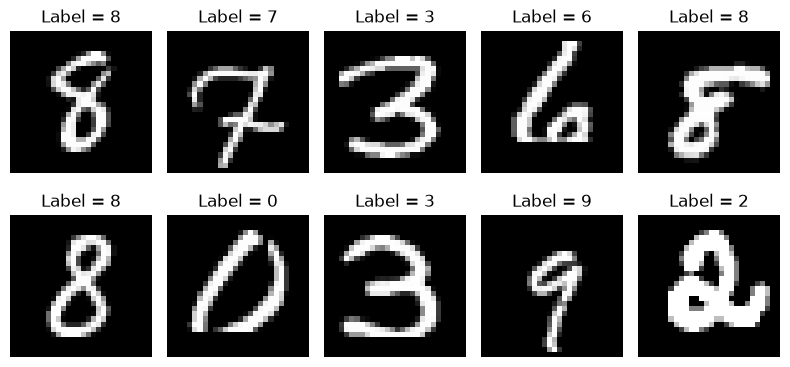

In [3]:
images, labels = next(iter(train_loader))
print(images.shape, labels.shape)

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),          # [1,28,28] -> 784
            nn.Linear(784, 128),   # couche cachée
            nn.ReLU(),
            nn.Linear(128, 10)     # 10 classes (logits)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

In [7]:
def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs} - Loss = {total_loss/len(loader):.4f}")

train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4171
Epoch 2/3 - Loss = 0.1896
Epoch 3/3 - Loss = 0.1362


In [8]:
def evaluate_classifier(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.37%


In [11]:
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_classifier_torcheval(model, loader):
    model.eval()
    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        metric.update(model(x), y)

    return metric.compute().item()

print(f"Accuracy (torcheval) = {100 * evaluate_classifier_torcheval(classifier, test_loader):.2f}%")

Accuracy (torcheval) = 96.37%


In [12]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()          # pixels dans [0,1]
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)

ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [13]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)

def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:          # on ignore les labels
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs} - Loss = {total_loss/len(loader):.4f}")

train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0662
Epoch 2/5 - Loss = 0.0525
Epoch 3/5 - Loss = 0.0501
Epoch 4/5 - Loss = 0.0479
Epoch 5/5 - Loss = 0.0462


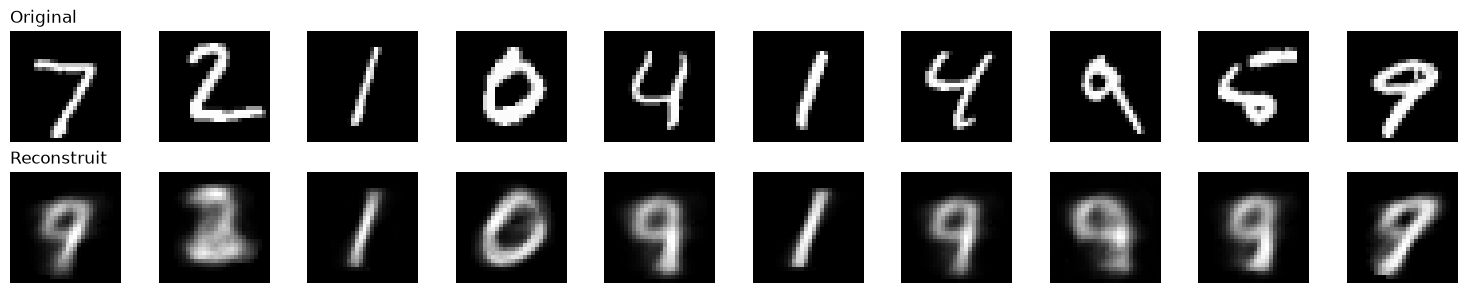

In [14]:
ae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat = ae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_title("Original", loc="left")
axes[1, 0].set_title("Reconstruit", loc="left")
plt.tight_layout()
plt.show()

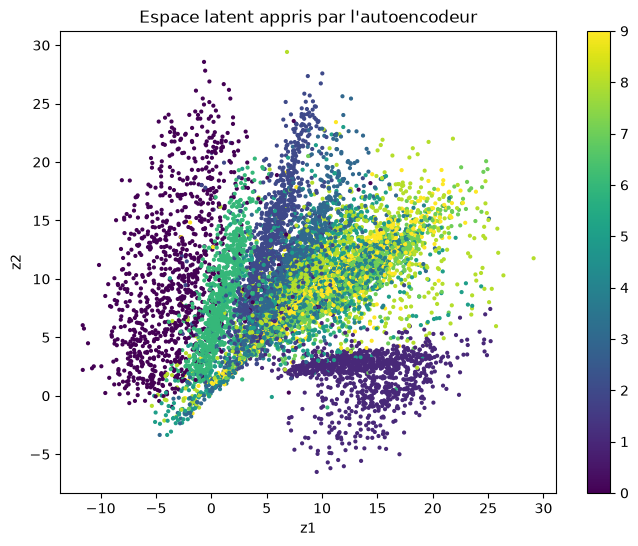

In [15]:
ae.eval()

zs, ys = [], []
with torch.no_grad():
    for x, y in test_loader:
        z = ae.encode(x.to(device))
        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4)
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'autoencodeur")
plt.colorbar(scatter)
plt.show()

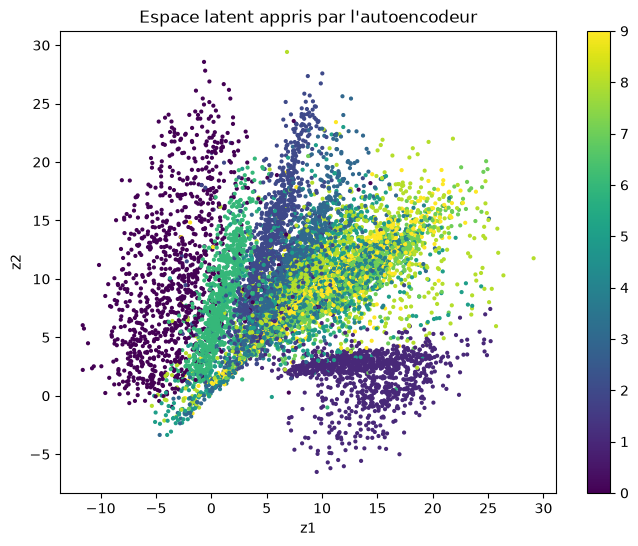

In [16]:
ae.eval()

zs, ys = [], []
with torch.no_grad():
    for x, y in test_loader:
        z = ae.encode(x.to(device))
        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4)
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'autoencodeur")
plt.colorbar(scatter)
plt.show()

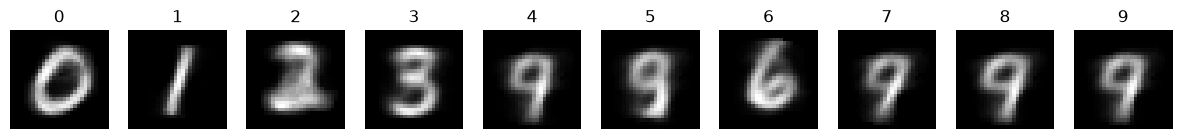

In [17]:
@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    model.eval()
    somme_z, nombre = None, 0

    for images, labels in dataloader:
        images = images[labels == chiffre]
        if images.shape[0] == 0:
            continue
        z = model.encode(images.to(device))
        somme_z = z.sum(dim=0, keepdim=True) if somme_z is None else somme_z + z.sum(dim=0, keepdim=True)
        nombre += z.shape[0]

    z_moyen = somme_z / nombre
    return model.decode(z_moyen).cpu()

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c in range(10):
    img = generer_chiffre(ae, train_loader, c)
    axes[c].imshow(img[0, 0], cmap="gray")
    axes[c].set_title(str(c))
    axes[c].axis("off")
plt.show()

# Partie III — VAE

In [19]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [20]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(x_hat, x, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return rec_loss + beta * kl_loss, rec_loss, kl_loss

In [21]:
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

def train_vae(model, loader, epochs=20, beta=1.0):
    model.train()

    for epoch in range(epochs):
        total_loss = total_rec = total_kl = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)
            loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta=beta)

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)
        print(f"Epoch {epoch+1}/{epochs} | Loss={total_loss/n:.2f} | Rec={total_rec/n:.2f} | KL={total_kl/n:.2f}")

train_vae(vae, train_loader, epochs=20)

Epoch 1/20 | Loss=194.78 | Rec=190.51 | KL=4.27
Epoch 2/20 | Loss=166.13 | Rec=161.07 | KL=5.05
Epoch 3/20 | Loss=160.69 | Rec=155.36 | KL=5.33
Epoch 4/20 | Loss=157.62 | Rec=152.16 | KL=5.46
Epoch 5/20 | Loss=155.48 | Rec=149.91 | KL=5.57
Epoch 6/20 | Loss=153.64 | Rec=147.94 | KL=5.70
Epoch 7/20 | Loss=151.93 | Rec=146.12 | KL=5.82
Epoch 8/20 | Loss=150.69 | Rec=144.80 | KL=5.89
Epoch 9/20 | Loss=149.63 | Rec=143.66 | KL=5.96
Epoch 10/20 | Loss=148.55 | Rec=142.51 | KL=6.04
Epoch 11/20 | Loss=147.81 | Rec=141.69 | KL=6.12
Epoch 12/20 | Loss=147.32 | Rec=141.17 | KL=6.15
Epoch 13/20 | Loss=146.98 | Rec=140.79 | KL=6.19
Epoch 14/20 | Loss=146.10 | Rec=139.88 | KL=6.22
Epoch 15/20 | Loss=145.61 | Rec=139.35 | KL=6.26
Epoch 16/20 | Loss=145.40 | Rec=139.11 | KL=6.29
Epoch 17/20 | Loss=144.91 | Rec=138.59 | KL=6.31
Epoch 18/20 | Loss=144.47 | Rec=138.12 | KL=6.36
Epoch 19/20 | Loss=144.09 | Rec=137.72 | KL=6.37
Epoch 20/20 | Loss=143.91 | Rec=137.52 | KL=6.40


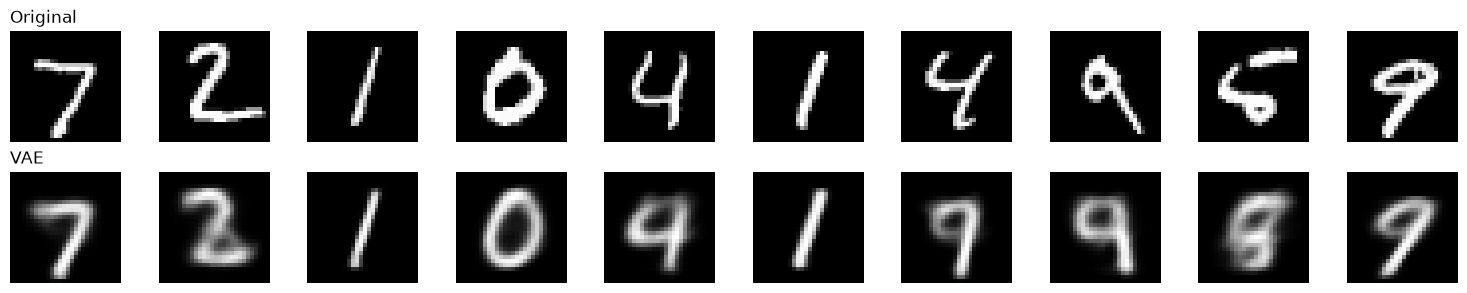

In [22]:
vae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_title("Original", loc="left")
axes[1, 0].set_title("VAE", loc="left")
plt.tight_layout()
plt.show()

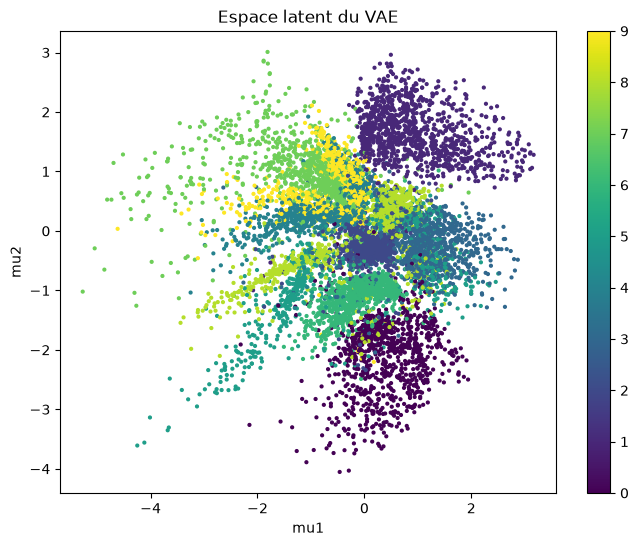

In [24]:
vae.eval()

mus, ys = [], []
with torch.no_grad():
    for x, y in test_loader:
        mu, logvar = vae.encode(x.to(device))
        mus.append(mu.cpu())
        ys.append(y)

MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(MU[:, 0], MU[:, 1], c=Y, s=4)
plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter)
plt.show()

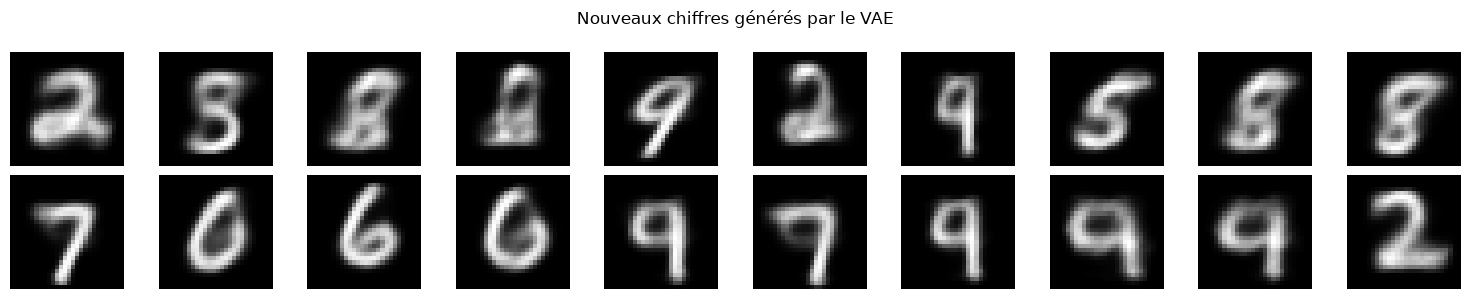

In [25]:
vae.eval()

with torch.no_grad():
    z = torch.randn(20, 2).to(device)    # z ~ N(0, I), sans image d'entrée
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("Nouveaux chiffres générés par le VAE")
plt.tight_layout()
plt.show()

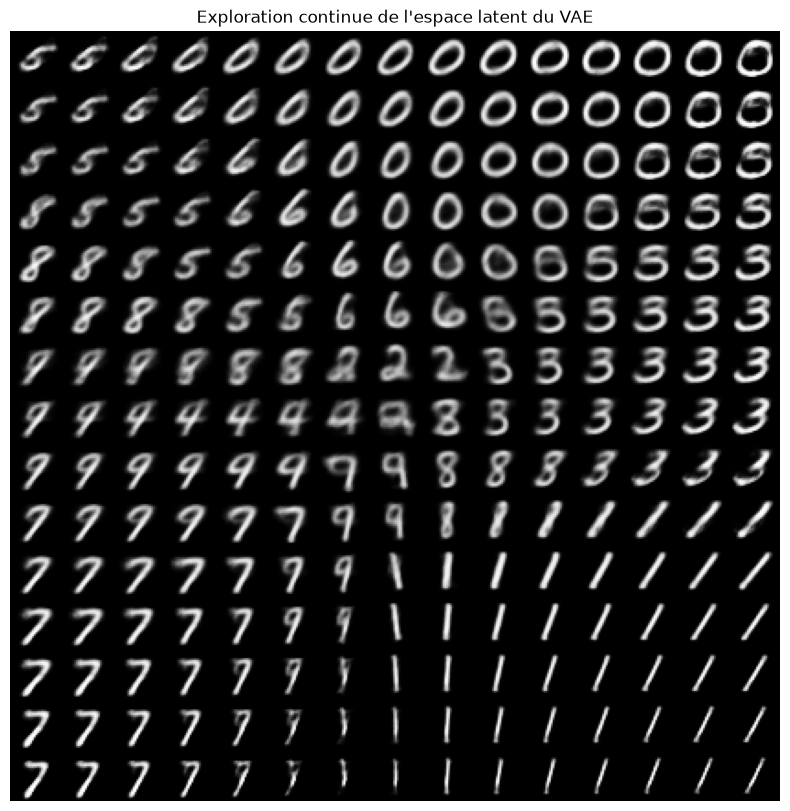

In [26]:
vae.eval()

grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(-3, 3, 15)
figure = np.zeros((28 * 15, 28 * 15))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z = torch.tensor([[xi, yi]], dtype=torch.float32, device=device)
            digit = vae.decode(z).cpu().numpy()[0, 0]
            figure[i*28:(i+1)*28, j*28:(j+1)*28] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de l'espace latent du VAE")
plt.show()